# Trabalho da Unidade 3 de PLN

**Marcos Borgert e Vitor Gustavo Hornburg**  
FURB - Processamento de Linguagem Natural - 2026/2

In [1]:
import sys

if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        "Selecione o kernel 'PLN Unidade 3 (Python 3.12)' antes de continuar. "
        f"O kernel atual usa Python {sys.version.split()[0]}."
    )

print("Python:", sys.version.split()[0])

# Instale somente se estiver preparando outro ambiente Python 3.12:
# %pip install -r requirements.txt
# %pip install https://github.com/explosion/spacy-models/releases/download/pt_core_news_sm-3.8.0/pt_core_news_sm-3.8.0-py3-none-any.whl


Python: 3.12.15


In [2]:
import os, re, json, hashlib, html, time, platform, importlib.metadata
from pathlib import Path
from itertools import combinations
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

get_ipython().run_line_magic("matplotlib", "inline")
import scipy.sparse as sparse
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from gensim.models import Word2Vec
import spacy

SEED = 42
np.random.seed(SEED)
BASE = Path.cwd()
if not (BASE / "dados/noticias_financeiras_brutas.csv").exists():
    raise FileNotFoundError(
        "Abra este notebook na pasta Unidade3_PLN, com a subpasta dados."
    )
RES = BASE / "resultados"
FIG = RES / "graficos"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.dpi": 130,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
pd.set_option("display.max_colwidth", 140)
status = {}


def salvar_csv(df, nome):
    df.to_csv(RES / nome, index=False, encoding="utf-8-sig")


def salvar_fig(nome):
    plt.tight_layout()
    plt.savefig(FIG / nome, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()


## 1. Preparação da base

Conferimos campos vazios e notícias repetidas, limpamos chamadas promocionais e juntamos título e corpo. O texto bruto continua salvo.

BoW, TF-IDF e Word2Vec usam tokens em minúsculas, sem stopwords e preservando a negação e os tickers. Lemas e radicais ficam em colunas separadas. Os rótulos de categoria e as URLs não entram no texto usado pelo classificador.


,registros_entrada,urls_duplicadas,titulos_duplicados,corpos_duplicados,registros_usados,paragrafos_promocionais_removidos
0,316,0,0,0,316,5


,doc_id,titulo,data_publicacao,tickers_encontrados
0,N001,"IFIX avança 0,43% e alcança 3.956,84 pontos",2026-10-19 19:08:54,"[""BRCR11"", ""CLIN11"", ""GARE11"", ""GGRC11"", ""MXRF11"", ""RZAT11"", ""SNEL11"", ""VGIR11"", ""VILG11""]"
1,N002,"Dividendos do MCRE11 superam 1,3% em outubro; veja quem recebe",2026-10-19 15:28:54,"[""MCRE11""]"
2,N003,"Por dentro do HGLG11: veja os galpões, contratos e dividendos do fundo",2026-10-19 13:08:55,"[""HGLG11""]"
3,N004,XPML11 anuncia dividendos para outubro; confira quem terá direito,2026-10-19 11:38:54,"[""XPML11""]"
4,N005,"Semana terá 65 pagamentos de FIIs, com dividend yield de até 1,69%",2026-10-19 11:18:54,"[""ALZR11"", ""CPOF11"", ""MANA11"", ""RZAK11"", ""VGIR11"", ""XPML11""]"
...,...,...,...,...
311,N312,Vale (VALE3) anuncia lucro 36% maior; confira os resultados do 1T26,2026-05-01 13:48:48,"[""VALE3""]"
312,N313,Petrobras (PETR4) fecha acordo para adquirir parte de campo; veja detalhes,2026-04-30 16:28:37,"[""PETR4""]"
313,N314,"Petrobras, Vale e mais: veja o calendário de resultados do 1T26",2026-04-27 14:38:37,"[""ASAI3"", ""AURE3"", ""BBAS3"", ""BBDC4"", ""BBSE3"", ""BEEF3"", ""CPLE6"", ""EGIE3"", ""GGBR4"", ""HYPE3"", ""IGTI11"", ""ITUB4"", ""KLBN11"", ""LREN3"", ""MGLU3""..."
314,N315,Banco do Brasil (BBAS3) faz estreia no mercado internacional e capta US$ 500 milhões; entenda,2026-04-24 17:18:51,"[""BBAS3""]"


,vazios
url,0
titulo,0
data_publicacao,0
autor,0
texto_bruto,0
tickers_encontrados,0
categoria,0
categoria_url,0
categoria_origem,0
paginas_descoberta,0


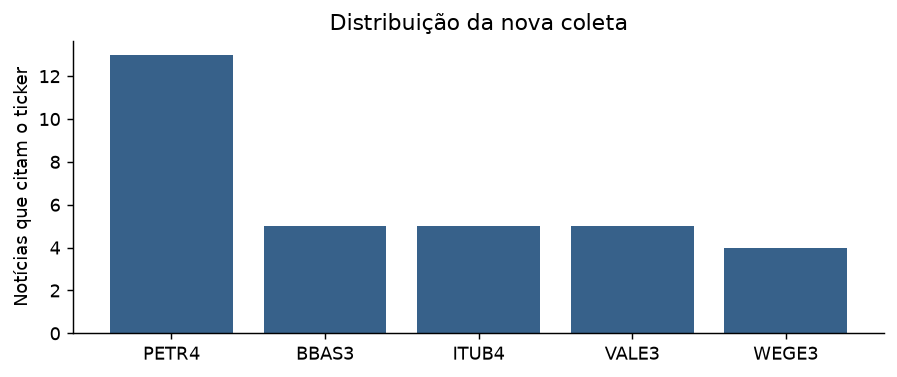

,noticias
categoria,
Negócios,116
FIIs,100
Fiagro,100


In [3]:
brutos = pd.read_csv(
    BASE / "dados/noticias_financeiras_brutas.csv", keep_default_na=False
)
obrigatorias = {"titulo", "texto_bruto", "url"}
assert obrigatorias.issubset(brutos.columns)
auditoria = {
    "registros_entrada": len(brutos),
    "ausentes": {c: int(brutos[c].eq("").sum()) for c in brutos},
    "urls_duplicadas": int(brutos.url.duplicated().sum()),
    "titulos_duplicados": int(brutos.titulo.duplicated().sum()),
    "corpos_duplicados": int(brutos.texto_bruto.duplicated().sum()),
}
df = brutos.loc[
    brutos.titulo.str.strip().ne("") & brutos.texto_bruto.str.len().ge(200)
].copy()
df = df.drop_duplicates("url").drop_duplicates("titulo").drop_duplicates("texto_bruto")
MAX_DOCS = 1000
if len(df) > MAX_DOCS:
    df = df.sample(MAX_DOCS, random_state=SEED).sort_index()
df = df.reset_index(drop=True)
df.insert(0, "doc_id", [f"N{i:03d}" for i in range(1, len(df) + 1)])
auditoria["registros_usados"] = len(df)
assert (
    len(df) >= 6
), "São necessárias pelo menos 6 notícias diferentes para esta comparação."
PROMO = r"Quer aprofundar sua avaliação|A Suno disponibiliza três livros|Baixe gratuitamente|Acesse os materiais aqui|Quer aprender a investir|Quer acompanhar notícias|Semana do Assinante da Suno"
auditoria["paragrafos_promocionais_removidos"] = sum(
    bool(re.search(PROMO, p, re.I)) for t in df.texto_bruto for p in t.splitlines()
)


def limpar(t):
    t = " ".join(p for p in str(t).splitlines() if not re.search(PROMO, p, re.I))
    t = html.unescape(str(t))
    t = re.sub(r"<[^>]+>", " ", t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"\bH[1-6]\s*:", " ", t, flags=re.I)
    return re.sub(r"\s+", " ", t).strip()


df["texto_limpo"] = df.texto_bruto.map(limpar)
df["texto_analise"] = df.titulo.map(limpar) + ". " + df.texto_limpo
stop = set(json.loads((BASE / "dados/stopwords_pt.json").read_text())) - {
    "não",
    "nem",
    "nunca",
    "sem",
}


def tokens(t):
    return [
        w
        for w in re.findall(r"(?u)\b[^\W_]+\b", t.casefold())
        if len(w) > 1 and not w.isdecimal() and w not in stop
    ]


df["tokens_sem_stopwords"] = df.texto_analise.map(tokens)
assert df.tokens_sem_stopwords.map(len).min() > 0
nlp = spacy.load("pt_core_news_sm")
from nltk.stem import RSLPStemmer
import nltk

nltk.data.path.insert(0, str(BASE / "dados/nltk_data"))
stemmer = RSLPStemmer()
docs = list(nlp.pipe(df.texto_analise, batch_size=16))
df["lemas"] = [
    [t.lemma_.casefold() for t in d if t.is_alpha and t.text.casefold() not in stop]
    for d in docs
]
df["stems"] = df.tokens_sem_stopwords.map(lambda xs: [stemmer.stem(x) for x in xs])
df.to_csv(
    BASE / "dados/noticias_financeiras_processadas.csv",
    index=False,
    encoding="utf-8-sig",
)
display(pd.DataFrame([auditoria]).drop(columns="ausentes"))
display(df[["doc_id", "titulo", "data_publicacao", "tickers_encontrados"]])
display(pd.Series(auditoria["ausentes"], name="vazios").to_frame())
datas = pd.to_datetime(df.data_publicacao, errors="coerce")
auditoria["publicacao_min"] = str(datas.min())
auditoria["publicacao_max"] = str(datas.max())
salvar_csv(
    df[["doc_id", "url", "titulo", "data_publicacao", "categoria", "texto_analise"]],
    "documentos.csv",
)
contagem = Counter(
    t
    for v in df.tickers_encontrados
    for t in json.loads(v)
    if t in {"PETR4", "VALE3", "ITUB4", "WEGE3", "BBAS3"}
)
plt.figure(figsize=(7, 3))
plt.bar(list(contagem), list(contagem.values()), color="#37618a")
plt.ylabel("Notícias que citam o ticker")
plt.title("Distribuição da nova coleta")
salvar_fig("01_tickers.png")
auditoria["categorias"] = df.categoria.value_counts().to_dict()
display(df.categoria.value_counts().to_frame("noticias"))


## 2. BoW, TF-IDF e Word2Vec

BoW conta as palavras e TF-IDF atribui pesos a elas. Os dois compartilham o mesmo vocabulário.

Treinamos Word2Vec com Skip-gram, 100 dimensões, janela 5, `min_count=2` e 60 épocas. Cada notícia é representada pela média das palavras conhecidas. Normalizamos os vetores antes da comparação.

Aqui a base completa é usada para agrupamento e busca. Na classificação, o vocabulário e o Word2Vec serão ajustados novamente usando somente o treino.


In [4]:
inicio = time.perf_counter()
vectorizer = CountVectorizer(
    analyzer=tokens, min_df=2 if len(df) >= 30 else 1, max_df=0.95, max_features=6000
)
counts = vectorizer.fit_transform(df.texto_analise)
tfidf = TfidfTransformer(norm="l2", sublinear_tf=True, smooth_idf=True)
Xt = tfidf.fit_transform(counts)
Xb = normalize(counts.astype(float))


def stable_hash(w):
    return int(hashlib.md5(w.encode()).hexdigest()[:8], 16)


w2v = Word2Vec(
    sentences=df.tokens_sem_stopwords.tolist(),
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=60,
    seed=SEED,
    workers=1,
    hashfxn=stable_hash,
)


def vetor_w2v(t):
    vs = [w2v.wv[w] for w in tokens(t) if w in w2v.wv]
    return np.mean(vs, axis=0) if vs else np.zeros(100, dtype=np.float32)


Xw = normalize(np.vstack([vetor_w2v(t) for t in df.texto_analise]))
representacoes = {"BoW": Xb, "TF-IDF": Xt, "Word2Vec": Xw}
status["lexicais_word2vec"] = {
    "realizado": True,
    "segundos": time.perf_counter() - inicio,
    "vocabulario": len(vectorizer.vocabulary_),
    "vocabulario_w2v": len(w2v.wv),
}
status["word2vec_cobertura"] = float(
    sum(w in w2v.wv for xs in df.tokens_sem_stopwords for w in xs)
    / sum(map(len, df.tokens_sem_stopwords))
)
assert np.linalg.norm(Xw, axis=1).min() > 0
print("Dimensões:", {k: v.shape for k, v in representacoes.items()})
print("Cobertura Word2Vec:", status["word2vec_cobertura"])


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Dimensões: {'BoW': (316, 4769), 'TF-IDF': (316, 4769), 'Word2Vec': (316, 100)}
Cobertura Word2Vec: 0.9636328476037721


### BERTimbau

Usamos `neuralmind/bert-base-portuguese-cased`, sem ajuste fino. A entrada mantém maiúsculas e pontuação. Dividimos notícias longas em blocos de até 254 subtokens e juntamos os vetores considerando o tamanho dos blocos.

O BERTimbau fica fixo durante todo o trabalho. Ele não foi ajustado para busca nem para as categorias desta base.


In [5]:
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

torch.set_num_threads(4)
modelos = json.loads((BASE / "dados/modelos.json").read_text())
CACHE = Path(os.environ.get("PLN_MODEL_CACHE", str(BASE / ".cache_modelos")))
bert_tok = bert_model = None


def carregar(key, classe):
    info = modelos[key]
    local = os.environ.get("PLN_MODEL_DIR")
    origem = str(Path(local) / key) if local else info["id"]
    return (
        AutoTokenizer.from_pretrained(
            origem, revision=info["revision"], cache_dir=CACHE
        ),
        classe.from_pretrained(
            origem, revision=info["revision"], cache_dir=CACHE
        ).eval(),
    )


def embedding_bert(textos):
    vetores = []
    with torch.inference_mode():
        for texto in textos:
            ids = bert_tok.encode(texto, add_special_tokens=False, truncation=False)
            total = np.zeros(bert_model.config.hidden_size, dtype=np.float64)
            n = 0
            for pos in range(0, len(ids), 254):
                bloco = ids[pos : pos + 254]
                entradas = bert_tok.prepare_for_model(
                    bloco, add_special_tokens=True, return_tensors="pt"
                )
                entradas = {
                    k: v.unsqueeze(0) if v.ndim == 1 else v for k, v in entradas.items()
                }
                h = bert_model(**entradas).last_hidden_state[0, 1:-1].cpu().numpy()
                total += h.sum(axis=0)
                n += len(h)
            vetores.append(total / max(n, 1))
    return normalize(np.array(vetores, dtype=np.float32))


try:
    inicio = time.perf_counter()
    bert_tok, bert_model = carregar("bert", AutoModel)
    Xbert = embedding_bert(df.texto_analise.tolist())
    assert np.isfinite(Xbert).all() and np.linalg.norm(Xbert, axis=1).min() > 0
    representacoes["BERT"] = Xbert
    status["BERT"] = {
        "realizado": True,
        "dimensoes": Xbert.shape[1],
        "segundos": time.perf_counter() - inicio,
    }
except Exception as erro:
    status["BERT"] = {"realizado": False, "motivo": repr(erro)}
print(status["BERT"])
assert status["BERT"][
    "realizado"
], "BERTimbau não foi executado; confira o erro acima antes de continuar."


/Users/vitor/furb/PLN/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


{'realizado': True, 'dimensoes': 768, 'segundos': 88.87694345897762}


## 3. Agrupamento das notícias

Testamos K-Means com 2 a 8 grupos, três sementes e 20 inicializações por ajuste. O PCA é aplicado depois, para visualização.

Comparamos silhueta, Davies-Bouldin, Calinski-Harabasz e distâncias dentro e entre os grupos. O ARI entre sementes indica estabilidade. Como agora temos categorias editoriais, também calculamos ARI e NMI em relação a essas categorias, sem usá-las para treinar o K-Means.

O K candidato usa a média da silhueta e evita grupos unitários quando há outra opção. A leitura das notícias continua necessária para interpretar os grupos.


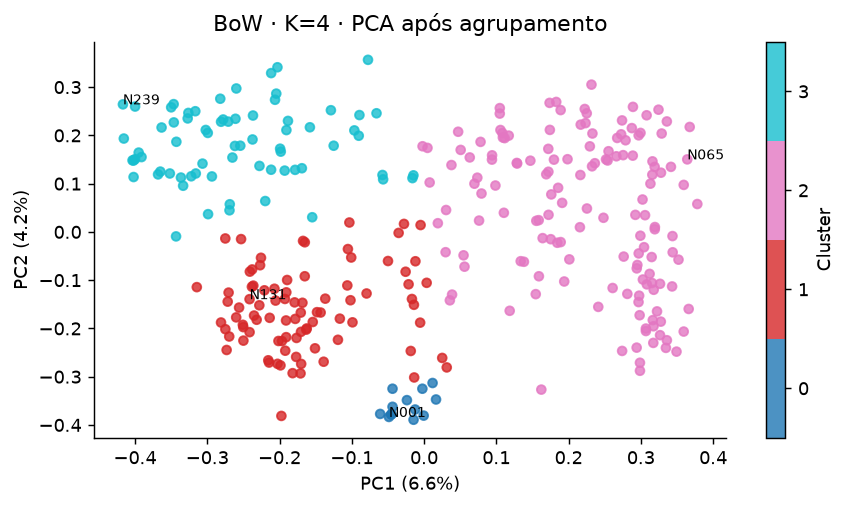

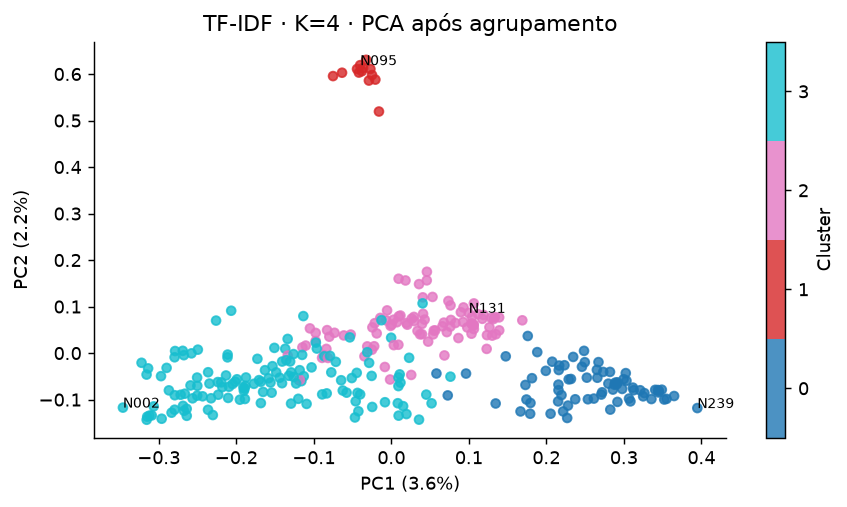

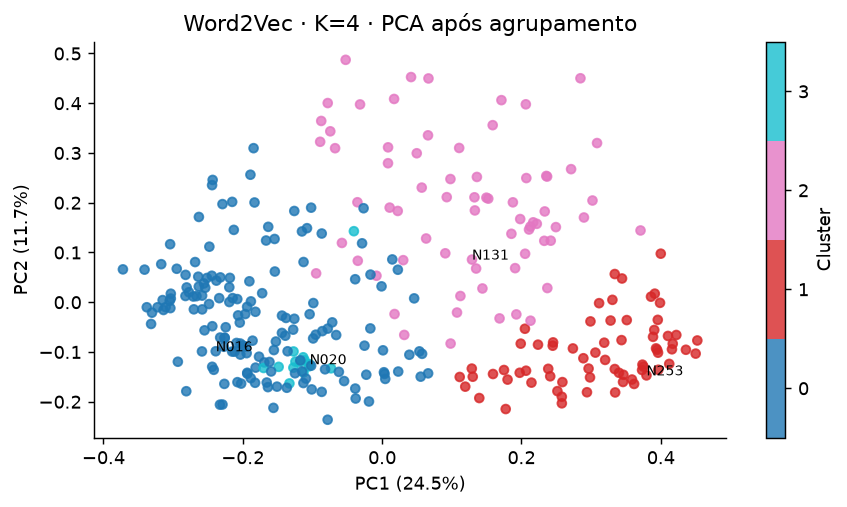

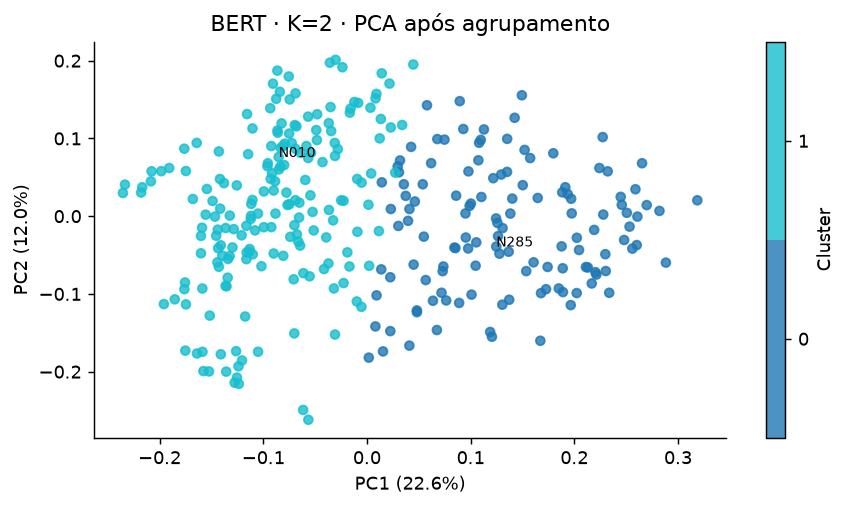

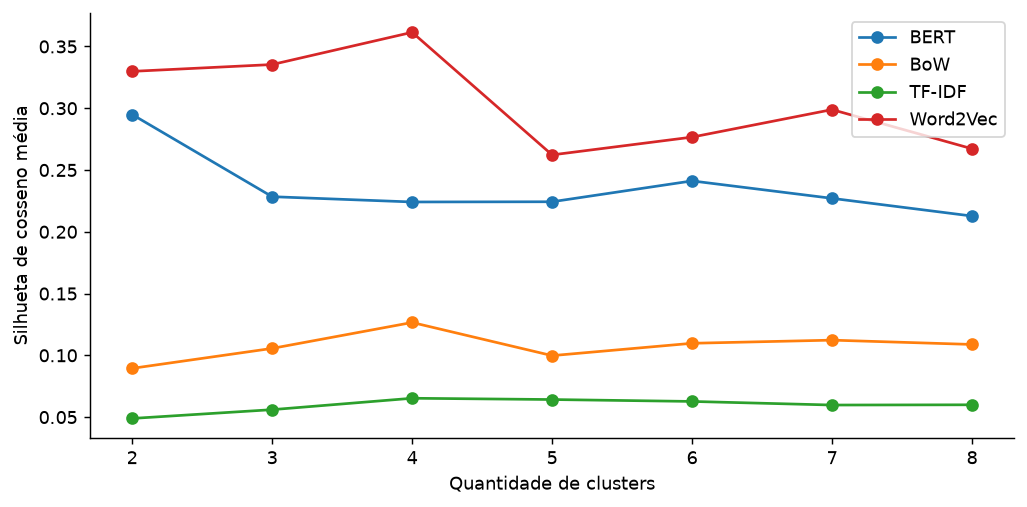

,representacao,k,ari_categorias,nmi_categorias,silhueta_cosseno,silhueta_euclidiana,davies_bouldin,calinski_harabasz,inercia,intra_media_quadratica,inter_centroides_media,estabilidade_ari,menor_cluster,maior_cluster
0,BERT,2,0.2113,0.2386,0.2949,0.1711,2.1202,64.5981,19.0882,0.0604,0.2278,0.9915,125,191
1,BERT,3,0.1868,0.2268,0.2284,0.1293,2.3213,49.7911,17.4601,0.0553,0.2276,0.9676,97,122
2,BERT,4,0.1948,0.2369,0.2241,0.1305,2.2376,42.3551,16.3546,0.0518,0.2426,0.8591,37,113
3,BERT,5,0.2569,0.3119,0.2243,0.1298,2.2371,38.9237,15.3370,0.0485,0.2611,0.9781,20,91
4,BERT,6,0.2585,0.3100,0.2412,0.1428,2.0096,36.3189,14.5134,0.0459,0.2922,0.9871,12,83
5,BERT,7,0.2408,0.3299,0.2271,0.1333,2.0046,34.0737,13.8510,0.0438,0.2894,0.9318,12,71
6,BERT,8,0.2447,0.3575,0.2127,0.1246,2.0241,31.4225,13.4266,0.0425,0.2865,0.8753,12,70
7,BoW,2,0.1052,0.0977,0.0895,0.0487,4.1082,18.1125,245.4736,0.7768,0.4256,0.9253,140,176
8,BoW,3,0.3038,0.3768,0.1056,0.0570,3.8897,15.1057,236.7789,0.7493,0.4778,0.8969,69,154
9,BoW,4,0.3414,0.4373,0.1266,0.0701,3.2700,13.8896,229.0437,0.7248,0.6694,0.8847,13,160


,representacao,k,cluster,ordem_central,doc_id,titulo,distancia_centro
0,BoW,4,0,1,N001,"IFIX avança 0,43% e alcança 3.956,84 pontos",0.465571
1,BoW,4,0,2,N064,"IFIX fecha em alta e encerra semana com avanço de 0,81%",0.497833
2,BoW,4,0,3,N095,"IFIX cai 0,37% e fecha pregão em 3.732,49 pontos",0.503053
3,BoW,4,1,1,N131,Petrobras (PETR4) melhora caixa e mantém tese de dividendos,0.870913
4,BoW,4,1,2,N112,Suzano detalha sinergias e metas de alavancagem,0.883606
5,BoW,4,1,3,N305,"Gestora global eleva aposta na Petrobras e passa a deter 5,03% das ações ordinárias",0.887518
6,BoW,4,2,1,N065,TGAR11: fundo imobiliário anuncia novos dividendos; veja valor,0.718088
7,BoW,4,2,2,N016,"KNCR11 divulgou resultados de setembro com 1,11% de yield mensal",0.729036
8,BoW,4,2,3,N071,"Fundo imobiliário RBVA11 anuncia novos dividendos de R$ 0,09 por cota",0.735907
9,BoW,4,3,1,N239,SNFZ11 surfa avanço do agro brasileiro que já superou meta global para 2050,0.754829


K candidato por representação: {'BoW': 4, 'TF-IDF': 4, 'Word2Vec': 4, 'BERT': 2}
Variância preservada no PCA: {'BoW': {'variancia_2d': 0.10802402995522539, 'k': 4}, 'TF-IDF': {'variancia_2d': 0.05810333283501239, 'k': 4}, 'Word2Vec': {'variancia_2d': 0.36271584033966064, 'k': 4}, 'BERT': {'variancia_2d': 0.34615832567214966, 'k': 2}}


In [6]:
from sklearn.metrics import normalized_mutual_info_score

metricas = []
ajustes = {}
candidatos = {}
centrais = []
membros = []
pca_info = {}
perfis = []
for nome, X in representacoes.items():
    A = X.toarray() if sparse.issparse(X) else X
    for k in range(2, min(8, len(df) - 1) + 1):
        ys = []
        linhas = []
        for seed in [7, 21, 42]:
            km = KMeans(n_clusters=k, random_state=seed, n_init=20, max_iter=500).fit(X)
            y = km.labels_
            ys.append(y)
            ajustes[nome, k, seed] = km
            tamanhos = np.bincount(y, minlength=k)
            if len(np.unique(y)) != k:
                continue
            d = euclidean_distances(km.cluster_centers_)
            row = {
                "representacao": nome,
                "k": k,
                "seed": seed,
                "ari_categorias": adjusted_rand_score(df.categoria, y),
                "nmi_categorias": normalized_mutual_info_score(df.categoria, y),
                "silhueta_cosseno": silhouette_score(X, y, metric="cosine"),
                "silhueta_euclidiana": silhouette_score(X, y, metric="euclidean"),
                "davies_bouldin": davies_bouldin_score(A, y),
                "calinski_harabasz": calinski_harabasz_score(A, y),
                "inercia": km.inertia_,
                "intra_media_quadratica": km.inertia_ / len(df),
                "inter_centroides_media": d[np.triu_indices(k, 1)].mean(),
                "menor_cluster": int(tamanhos.min()),
                "maior_cluster": int(tamanhos.max()),
            }
            linhas.append(row)
        ari = float(
            np.mean([adjusted_rand_score(a, b) for a, b in combinations(ys, 2)])
        )
        for row in linhas:
            row["estabilidade_ari"] = ari
            metricas.append(row)
met = pd.DataFrame(metricas)
assert not met.empty
salvar_csv(met, "metricas_clusters_todas_sementes.csv")
medias = (
    met.groupby(["representacao", "k"], as_index=False)
    .mean(numeric_only=True)
    .drop(columns="seed")
)
limites = met.groupby(["representacao", "k"], as_index=False).agg(
    menor_cluster=("menor_cluster", "min"), maior_cluster=("maior_cluster", "max")
)
medias = medias.drop(columns=["menor_cluster", "maior_cluster"]).merge(
    limites, on=["representacao", "k"]
)
salvar_csv(medias, "metricas_clusters_medias.csv")
for nome, X in representacoes.items():
    tabela = medias[medias.representacao.eq(nome)]
    validos = tabela[tabela.menor_cluster.ge(2)]
    if validos.empty:
        validos = tabela
    k = int(
        validos.sort_values(["silhueta_cosseno", "k"], ascending=[False, True])
        .iloc[0]
        .k
    )
    candidatos[nome] = k
    km = ajustes[nome, k, 42]
    y = km.labels_
    A = X.toarray() if sparse.issparse(X) else X
    pca = PCA(n_components=2, svd_solver="full")
    coords = pca.fit_transform(A)
    pca_info[nome] = {
        "variancia_2d": float(pca.explained_variance_ratio_.sum()),
        "k": k,
    }
    plt.figure(figsize=(7, 4))
    sc = plt.scatter(
        coords[:, 0],
        coords[:, 1],
        c=y,
        cmap=plt.get_cmap("tab10", k),
        vmin=-0.5,
        vmax=k - 0.5,
        s=24,
        alpha=0.8,
    )
    plt.colorbar(sc, ticks=range(k), label="Cluster")
    for c in range(k):
        idx = np.flatnonzero(y == c)
        pesos = np.asarray(Xt[idx].mean(axis=0)).ravel()
        termos = vectorizer.get_feature_names_out()[np.argsort(-pesos)[:10]]
        perfis.append(
            {
                "representacao": nome,
                "cluster": c,
                "quantidade": len(idx),
                "termos_tfidf": ", ".join(termos),
            }
        )
        dist = euclidean_distances(X[idx], km.cluster_centers_[c : c + 1]).ravel()
        ordem = idx[np.argsort(dist)]
        for rank, i in enumerate(ordem[:3], 1):
            centrais.append(
                {
                    "representacao": nome,
                    "k": k,
                    "cluster": c,
                    "ordem_central": rank,
                    "doc_id": df.iloc[i].doc_id,
                    "titulo": df.iloc[i].titulo,
                    "distancia_centro": float(dist[np.argsort(dist)[rank - 1]]),
                }
            )
        j = int(ordem[0])
        plt.annotate(df.iloc[j].doc_id, coords[j], fontsize=8)
        for i in idx:
            membros.append(
                {"representacao": nome, "cluster": c, "doc_id": df.iloc[i].doc_id}
            )
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    plt.title(f"{nome} · K={k} · PCA após agrupamento")
    salvar_fig("pca_" + nome.replace("-", "_") + ".png")
plt.figure(figsize=(8, 4))
for nome, g in medias.groupby("representacao"):
    plt.plot(g.k, g.silhueta_cosseno, marker="o", label=nome)
plt.xlabel("Quantidade de clusters")
plt.ylabel("Silhueta de cosseno média")
plt.legend()
salvar_fig("02_silhueta.png")
centrais = pd.DataFrame(centrais)
salvar_csv(centrais, "documentos_centrais.csv")
salvar_csv(pd.DataFrame(membros), "membros_clusters.csv")
salvar_csv(pd.DataFrame(perfis), "perfis_clusters.csv")
display(medias.round(4))
display(centrais)
print("K candidato por representação:", candidatos)
print("Variância preservada no PCA:", pca_info)


## 4. Busca por notícias

Usamos sete consultas iguais nos quatro modelos. Mantivemos as cinco consultas sobre ações e acrescentamos uma sobre fundos imobiliários e outra sobre o agronegócio.

Ordenamos as notícias pela similaridade de cosseno. O top 3 são as três primeiras linhas do top 5. Se uma consulta não tem palavras conhecidas, registramos a falta de cobertura. As pontuações ordenam os resultados de cada modelo; não são probabilidades.


In [7]:
CONSULTAS = [
    "Petrobras dividendos",
    "Vale produção minério de ferro",
    "Itaú lucro resultado",
    "WEG receita lucro",
    "Banco do Brasil dividendos",
    "dividendos fundos imobiliários",
    "agronegócio CRA rendimentos",
]


def vetor_consulta(nome, q):
    if nome == "BoW":
        return normalize(vectorizer.transform([q]).astype(float))
    if nome == "TF-IDF":
        return tfidf.transform(vectorizer.transform([q]))
    if nome == "Word2Vec":
        return normalize(vetor_w2v(q).reshape(1, -1))
    return embedding_bert([q])


buscas = []
cobertura = []
for nome, X in representacoes.items():
    for q in CONSULTAS:
        v = vetor_consulta(nome, q)
        norma = float(
            sparse.linalg.norm(v) if sparse.issparse(v) else np.linalg.norm(v)
        )
        cobertura.append(
            {"representacao": nome, "consulta": q, "consulta_coberta": norma > 0}
        )
        if norma == 0:
            continue
        scores = cosine_similarity(v, X).ravel()
        for rank, i in enumerate(np.argsort(-scores, kind="stable")[:5], 1):
            buscas.append(
                {
                    "representacao": nome,
                    "consulta": q,
                    "rank": rank,
                    "doc_id": df.iloc[i].doc_id,
                    "score": float(scores[i]),
                    "titulo": df.iloc[i].titulo,
                    "url": df.iloc[i].url,
                }
            )
buscas = pd.DataFrame(buscas)
salvar_csv(buscas, "buscas_top5.csv")
salvar_csv(pd.DataFrame(cobertura), "cobertura_consultas.csv")
for q in CONSULTAS:
    print("CONSULTA:", q)
    display(
        buscas[buscas.consulta.eq(q)][
            ["representacao", "rank", "doc_id", "score", "titulo"]
        ]
    )
# Concordância entre rankings é apenas diagnóstico, sem equivaler à relevância.
acordos = []
for q in CONSULTAS:
    for a, b in combinations(representacoes, 2):
        for k in [3, 5]:
            sa = set(
                buscas[
                    (buscas.consulta == q)
                    & (buscas.representacao == a)
                    & (buscas["rank"] <= k)
                ].doc_id
            )
            sb = set(
                buscas[
                    (buscas.consulta == q)
                    & (buscas.representacao == b)
                    & (buscas["rank"] <= k)
                ].doc_id
            )
            acordos.append(
                {
                    "consulta": q,
                    "a": a,
                    "b": b,
                    "top": k,
                    "jaccard": len(sa & sb) / len(sa | sb) if sa | sb else np.nan,
                }
            )
salvar_csv(pd.DataFrame(acordos), "concordancia_rankings.csv")


CONSULTA: Petrobras dividendos


,representacao,rank,doc_id,score,titulo
0,BoW,1,N136,0.323989,Petrobras (PETR4) ou PRIO (PRIO3): quem vence esse duelo do petróleo?
1,BoW,2,N132,0.245678,"Petrobras (PETR4) vai pagar R$ 17,4 bilhões em proventos"
2,BoW,3,N131,0.226921,Petrobras (PETR4) melhora caixa e mantém tese de dividendos
3,BoW,4,N304,0.202113,Petrobras (PETR4) fecha R$ 60 bilhões em contratos; entenda
4,BoW,5,N303,0.194331,Petrobras supera Prio (PRIO3) em trade de valor relativo da EQI
35,TF-IDF,1,N136,0.209837,Petrobras (PETR4) ou PRIO (PRIO3): quem vence esse duelo do petróleo?
36,TF-IDF,2,N304,0.174648,Petrobras (PETR4) fecha R$ 60 bilhões em contratos; entenda
37,TF-IDF,3,N132,0.169602,"Petrobras (PETR4) vai pagar R$ 17,4 bilhões em proventos"
38,TF-IDF,4,N303,0.164659,Petrobras supera Prio (PRIO3) em trade de valor relativo da EQI
39,TF-IDF,5,N313,0.160904,Petrobras (PETR4) fecha acordo para adquirir parte de campo; veja detalhes


CONSULTA: Vale produção minério de ferro


,representacao,rank,doc_id,score,titulo
5,BoW,1,N308,0.306754,Vale (VALE3) eleva projeções e prevê ganho extra bilionário em 2026
6,BoW,2,N309,0.173205,BTG eleva preço-alvo da Vale (VALE3); veja o que se espera das ações da mineradora
7,BoW,3,N312,0.170986,Vale (VALE3) anuncia lucro 36% maior; confira os resultados do 1T26
8,BoW,4,N222,0.142160,JBS capta R$ 400 mi para operação de biodiesel; cadeia do agro é acompanhada pelo SNFZ11
9,BoW,5,N284,0.131762,EUA eleva estimativa de produção brasileira de milho; veja impacto para fiagro
40,TF-IDF,1,N308,0.328177,Vale (VALE3) eleva projeções e prevê ganho extra bilionário em 2026
41,TF-IDF,2,N312,0.278269,Vale (VALE3) anuncia lucro 36% maior; confira os resultados do 1T26
42,TF-IDF,3,N309,0.206803,BTG eleva preço-alvo da Vale (VALE3); veja o que se espera das ações da mineradora
43,TF-IDF,4,N122,0.055003,Ambev entra no top 10 de ações mais negociadas em julho
44,TF-IDF,5,N101,0.041894,TSMC: como investir via BDRs na B3 e riscos


CONSULTA: Itaú lucro resultado


...

,representacao,rank,doc_id,score,titulo
20,BoW,1,N134,0.347587,"Itaúsa (ITSA4) ou Itaú (ITUB4): holding ou banco, quem paga mais dividendos?"
21,BoW,2,N107,0.300341,Ações do Banco do Brasil sobem 26% e analistas cautelosos
22,BoW,3,N315,0.259808,Banco do Brasil (BBAS3) faz estreia no mercado internacional e capta US$ 500 milhões; entenda
23,BoW,4,N105,0.193971,"Aumento de capital do Bradesco chega a R$ 103,77 bi"
24,BoW,5,N191,0.162136,PetroReconcavo (RECV3) tem “upgrade” do Citi e foco em dividendos
55,TF-IDF,1,N134,0.169942,"Itaúsa (ITSA4) ou Itaú (ITUB4): holding ou banco, quem paga mais dividendos?"
56,TF-IDF,2,N315,0.154613,Banco do Brasil (BBAS3) faz estreia no mercado internacional e capta US$ 500 milhões; entenda
57,TF-IDF,3,N107,0.150810,Ações do Banco do Brasil sobem 26% e analistas cautelosos
58,TF-IDF,4,N123,0.133352,"Letras financeiras: Santander Brasil capta R$ 600,3 mi"
59,TF-IDF,5,N170,0.129659,"Com yields acima de 1%, CPTS11 e RZAK11 pagam dividendos hoje (22)"


CONSULTA: dividendos fundos imobiliários


,representacao,rank,doc_id,score,titulo
25,BoW,1,N033,0.323381,"Dividendos de 180 FIIs são anunciados com yield de até 3,31%"
26,BoW,2,N010,0.305293,Dividendos do RBRX11 superam 1% de yield; veja quem tem direito
27,BoW,3,N164,0.299865,ALZC11 e mais FIIs pagam dividendos nesta terça-feira (23)
28,BoW,4,N052,0.288675,"CPTS11 vê lucro avançar 43% e dividendos entregam yield de 1,20%"
29,BoW,5,N043,0.287195,Dividendos hoje: três FIIs fazem pagamentos nesta sexta-feira (9)
60,TF-IDF,1,N043,0.155488,Dividendos hoje: três FIIs fazem pagamentos nesta sexta-feira (9)
61,TF-IDF,2,N052,0.152840,"CPTS11 vê lucro avançar 43% e dividendos entregam yield de 1,20%"
62,TF-IDF,3,N170,0.151305,"Com yields acima de 1%, CPTS11 e RZAK11 pagam dividendos hoje (22)"
63,TF-IDF,4,N184,0.149818,RBRR11 e RBRY11 estão entre os FIIs que pagam dividendos nesta quarta (17)
64,TF-IDF,5,N013,0.147943,FIIs pagam hoje (16) aos cotistas que tem direito; veja valores


CONSULTA: agronegócio CRA rendimentos


,representacao,rank,doc_id,score,titulo
30,BoW,1,N224,0.224055,Brasil e Índia ampliam aproximação e podem abrir novas oportunidades para Fiagros
31,BoW,2,N221,0.194143,Abertura de 651 mercados ao agro reforça perspectiva para Fiagros como SNAG11
32,BoW,3,N232,0.172774,SNFZ11 deposita dividendos com yield superior a 12% ao ano; veja detalhes
33,BoW,4,N257,0.170400,OIAG11 reforça caixa e amplia foco no agro após abril
34,BoW,5,N258,0.167789,"IAAG11 confirma R$ 0,12 por cota e eleva carrego a CDI +3,1%"
65,TF-IDF,1,N206,0.164488,"XPCA11 registra perda milionária, mas mantém dividendos com retorno acima de 1%"
66,TF-IDF,2,N258,0.164243,"IAAG11 confirma R$ 0,12 por cota e eleva carrego a CDI +3,1%"
67,TF-IDF,3,N205,0.149303,"VGIA11 aumenta lucro em 27,56% e dividendos rendem 1,20% no mês"
68,TF-IDF,4,N257,0.142605,OIAG11 reforça caixa e amplia foco no agro após abril
69,TF-IDF,5,N277,0.130433,IAAG11 amplia crédito privado e mantém dividendos estáveis


## 5. Classificação das categorias editoriais

Agora temos três rótulos publicados pelo site: FIIs, Negócios e Fiagro. A tarefa é prever essa editoria, que pode ter sobreposição de assuntos e erros de organização do próprio site.

Separamos cerca de 80% das notícias para treino e 20% para teste. Títulos com o mesmo molde ou similaridade muito alta ficam no mesmo grupo e não atravessam a divisão. Dentro do treino, fazemos validação em três partes para escolher a representação pelo F1 macro.

BoW, TF-IDF e Word2Vec são ajustados só nos respectivos textos de treino, inclusive na validação. BERTimbau fornece vetores fixos, sem ajuste fino. O modelo de decisão é Regressão Logística.

Avaliamos as três categorias e também FIIs versus as demais editorias. As frases novas no fim são apenas exemplos de uso e não entram nas métricas. As probabilidades não foram calibradas.


Treino: 253 | Teste: 63 | Grupos: 310


particao,teste,treino
categoria,,
FIIs,20,80
Fiagro,20,80
Negócios,23,93


Validação BoW 1
Validação BoW 2
Validação BoW 3
Validação TF-IDF 1
Validação TF-IDF 2
Validação TF-IDF 3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Validação Word2Vec 1
Validação Word2Vec 2


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Validação Word2Vec 3
Validação BERT 1
Validação BERT 2
Validação BERT 3


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


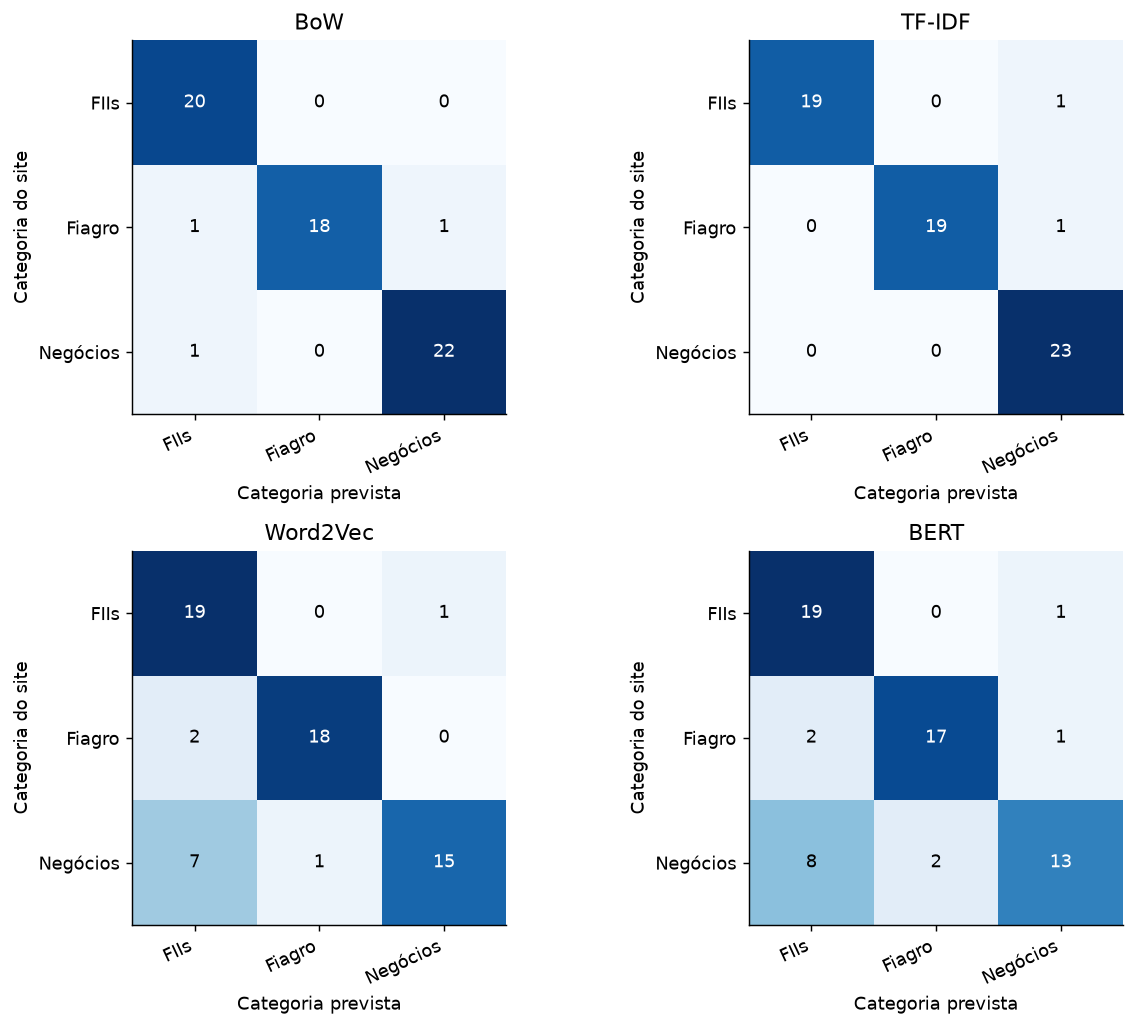

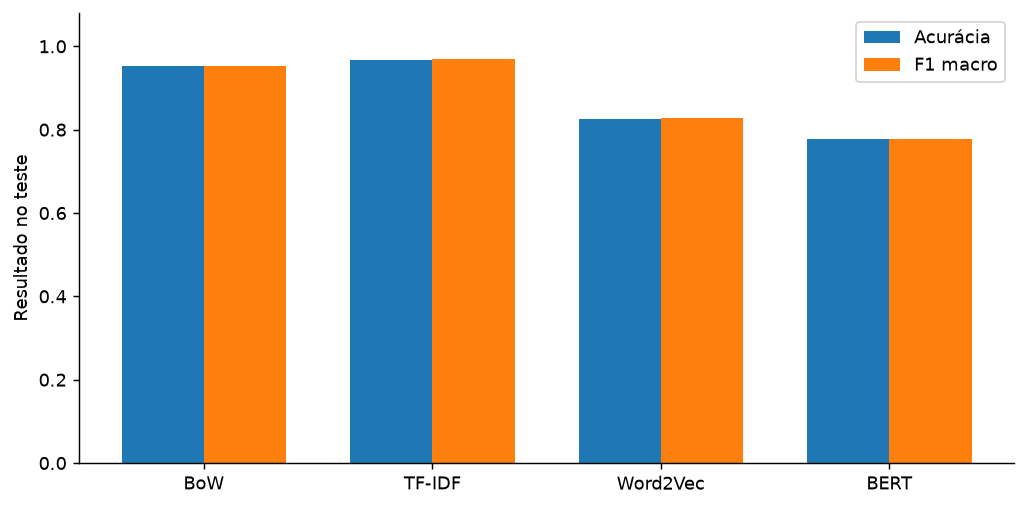

,representacao,acuracia,precisao_macro,revocacao_macro,f1_macro,f1_macro_validacao,treino,teste,escolhido_na_validacao
0,BoW,0.9524,0.9552,0.9522,0.9521,0.9067,253,63,False
1,TF-IDF,0.9683,0.9733,0.9667,0.9690,0.9294,253,63,True
2,Word2Vec,0.8254,0.8545,0.8341,0.8280,0.8189,253,63,False
3,BERT,0.7778,0.8055,0.7884,0.7772,0.7361,253,63,False


,representacao,acuracia,f1_macro,f1_fiis
0,BoW,0.9524,0.9458,0.9268
1,TF-IDF,0.9841,0.9814,0.9744
2,Word2Vec,0.8413,0.8317,0.7917
3,BERT,0.8413,0.8317,0.7917


Modelo escolhido pela validação do treino: TF-IDF


,texto,categoria_esperada_ilustrativa,categoria_prevista,probabilidade_max,modelo
0,A empresa ampliou o lucro e anunciou a distribuição de dividendos aos acionistas.,Negócios,Negócios,0.625139,TF-IDF
1,A fabricante divulgou crescimento da receita e vai investir em uma nova unidade industrial.,Negócios,Negócios,0.528380,TF-IDF
2,O fundo imobiliário comprou um galpão logístico e reduziu a vacância da carteira.,FIIs,Negócios,0.494651,TF-IDF
3,O fundo de shopping centers anunciou rendimentos mensais aos cotistas.,FIIs,Negócios,0.427574,TF-IDF
4,O fundo do agronegócio comprou certificados de recebíveis ligados à produção de soja.,Fiagro,Fiagro,0.512779,TF-IDF
5,O Fiagro anunciou a compra de uma fazenda e novos investimentos em CRAs.,Fiagro,Fiagro,0.479939,TF-IDF


In [8]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
    normalized_mutual_info_score,
)


# Agrupamos títulos com o mesmo molde para evitar cópias quase iguais no treino e teste.
def molde_titulo(titulo):
    titulo = re.sub(r"\b[A-Z]{4}\d{1,2}\b", " ATIVO ", titulo)
    titulo = re.sub(r"\d+(?:[.,]\d+)*", " NUMERO ", titulo)
    return " ".join(re.findall(r"\w+", titulo.casefold()))


moldes = df.titulo.map(molde_titulo)
pais = list(range(len(df)))


def raiz(i):
    while pais[i] != i:
        pais[i] = pais[pais[i]]
        i = pais[i]
    return i


def unir(a, b):
    a, b = raiz(a), raiz(b)
    if a != b:
        pais[b] = a


vistos = {}
for i, molde in enumerate(moldes):
    if molde in vistos:
        unir(i, vistos[molde])
    vistos[molde] = i
# Uma segunda conferência encontra títulos muito próximos, mesmo com pequenas mudanças.
vetor_grupos = CountVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1)
G = normalize(vetor_grupos.fit_transform(moldes))
proximidade = cosine_similarity(G)
for i, j in zip(*np.where(np.triu(proximidade, 1) >= 0.92)):
    unir(int(i), int(j))
grupos = np.array([raiz(i) for i in range(len(df))])
y = df.categoria.to_numpy()
classes = sorted(set(y))
assert len(classes) == 3
salvar_csv(
    df[["doc_id", "titulo", "categoria"]].assign(grupo=grupos),
    "grupos_classificacao.csv",
)

# O teste fica reservado. A comparação para escolher o modelo usa só o treino.
particao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
treino, teste = next(particao.split(df, y, grupos))
assert not set(grupos[treino]) & set(grupos[teste])
assert set(y[treino]) == set(y[teste]) == set(classes)
assert not set(df.iloc[treino].url) & set(df.iloc[teste].url)
particoes = df[["doc_id", "url", "titulo", "categoria"]].copy()
particoes["grupo"] = grupos
particoes["particao"] = "treino"
particoes.loc[teste, "particao"] = "teste"
salvar_csv(particoes, "particoes_classificacao.csv")
print("Treino:", len(treino), "| Teste:", len(teste), "| Grupos:", len(set(grupos)))
display(pd.crosstab(particoes.categoria, particoes.particao))


# Cada ajuste de vocabulário ou Word2Vec vê somente os textos do respectivo treino.
def preparar_classificacao(nome, idx_treino, idx_destino):
    textos_treino = df.iloc[idx_treino].texto_analise
    textos_destino = df.iloc[idx_destino].texto_analise
    if nome in ["BoW", "TF-IDF"]:
        contador = CountVectorizer(
            analyzer=tokens, min_df=2, max_df=0.95, max_features=6000
        )
        A = contador.fit_transform(textos_treino)
        B = contador.transform(textos_destino)
        ponderador = None
        if nome == "TF-IDF":
            ponderador = TfidfTransformer(norm="l2", sublinear_tf=True, smooth_idf=True)
            A = ponderador.fit_transform(A)
            B = ponderador.transform(B)
        else:
            A, B = normalize(A.astype(float)), normalize(B.astype(float))
        return A, B, {"contador": contador, "ponderador": ponderador}
    if nome == "Word2Vec":
        modelo = Word2Vec(
            sentences=[tokens(t) for t in textos_treino],
            vector_size=100,
            window=5,
            min_count=2,
            sg=1,
            epochs=60,
            seed=SEED,
            workers=1,
            hashfxn=stable_hash,
        )

        def transformar(textos):
            linhas = []
            for t in textos:
                conhecidos = [modelo.wv[w] for w in tokens(t) if w in modelo.wv]
                linhas.append(
                    np.mean(conhecidos, axis=0) if conhecidos else np.zeros(100)
                )
            return normalize(np.asarray(linhas))

        return transformar(textos_treino), transformar(textos_destino), {"w2v": modelo}
    # BERTimbau é fixo, pré-treinado externamente e não recebe os rótulos da base.
    return Xbert[idx_treino], Xbert[idx_destino], {}


validacao = []
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=21)
nomes = list(representacoes)
for nome in nomes:
    for fold, (a, b) in enumerate(
        cv.split(df.iloc[treino], y[treino], grupos[treino]), 1
    ):
        it, iv = treino[a], treino[b]
        A, B, _ = preparar_classificacao(nome, it, iv)
        modelo = LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=SEED
        )
        modelo.fit(A, y[it])
        pred = modelo.predict(B)
        validacao.append(
            {
                "representacao": nome,
                "fold": fold,
                "acuracia": accuracy_score(y[iv], pred),
                "f1_macro": f1_score(y[iv], pred, average="macro", zero_division=0),
            }
        )
        print("Validação", nome, fold, flush=True)
validacao = pd.DataFrame(validacao)
salvar_csv(validacao, "validacao_classificacao.csv")
medias_cv = validacao.groupby("representacao", as_index=False)[
    ["acuracia", "f1_macro"]
].mean()
melhor_nome = (
    medias_cv.sort_values(["f1_macro", "representacao"], ascending=[False, True])
    .iloc[0]
    .representacao
)

resultados_class = []
previsoes = []
relatorios = []
modelos_class = {}
binarios = []
fig, eixos = plt.subplots(2, 2, figsize=(10, 8))
for ax, nome in zip(eixos.ravel(), nomes):
    A, B, recursos = preparar_classificacao(nome, treino, teste)
    modelo = LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED
    )
    modelo.fit(A, y[treino])
    pred = modelo.predict(B)
    prob = modelo.predict_proba(B)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y[teste], pred, average="macro", zero_division=0
    )
    resultados_class.append(
        {
            "representacao": nome,
            "acuracia": accuracy_score(y[teste], pred),
            "precisao_macro": precision,
            "revocacao_macro": recall,
            "f1_macro": f1,
            "f1_macro_validacao": float(
                medias_cv.loc[medias_cv.representacao == nome, "f1_macro"].iloc[0]
            ),
            "treino": len(treino),
            "teste": len(teste),
            "escolhido_na_validacao": nome == melhor_nome,
        }
    )
    rel = classification_report(
        y[teste], pred, labels=classes, output_dict=True, zero_division=0
    )
    for classe in classes:
        relatorios.append({"representacao": nome, "categoria": classe, **rel[classe]})
    for pos, (i, p, probs) in enumerate(zip(teste, pred, prob)):
        previsoes.append(
            {
                "representacao": nome,
                "doc_id": df.iloc[i].doc_id,
                "titulo": df.iloc[i].titulo,
                "categoria_real": y[i],
                "categoria_prevista": p,
                "probabilidade_max": float(probs.max()),
                "acerto": p == y[i],
            }
        )
    cm = confusion_matrix(y[teste], pred, labels=classes)
    ax.imshow(cm, cmap="Blues")
    for a in range(len(classes)):
        for b in range(len(classes)):
            ax.text(
                b,
                a,
                str(cm[a, b]),
                ha="center",
                va="center",
                color="white" if cm[a, b] > cm.max() / 2 else "black",
            )
    ax.set_xticks(range(len(classes)), classes, rotation=25, ha="right")
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel("Categoria prevista")
    ax.set_ylabel("Categoria do site")
    ax.set_title(nome)
    salvar_csv(
        pd.DataFrame(cm, index=classes, columns=classes).reset_index(
            names="categoria_real"
        ),
        "confusao_" + nome.replace("-", "_") + ".csv",
    )
    modelos_class[nome] = (modelo, recursos)
    # Segunda tarefa: FIIs versus as outras duas editorias.
    ybin = (y == "FIIs").astype(int)
    mb = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    mb.fit(A, ybin[treino])
    pb = mb.predict(B)
    binarios.append(
        {
            "representacao": nome,
            "acuracia": accuracy_score(ybin[teste], pb),
            "f1_macro": f1_score(ybin[teste], pb, average="macro", zero_division=0),
            "f1_fiis": f1_score(ybin[teste], pb, zero_division=0),
        }
    )
salvar_fig("05_matrizes_classificacao.png")
base_dummy = DummyClassifier(strategy="most_frequent").fit(
    np.zeros((len(treino), 1)), y[treino]
)
dummy = base_dummy.predict(np.zeros((len(teste), 1)))
classificacao = pd.DataFrame(resultados_class)
salvar_csv(classificacao, "metricas_classificacao.csv")
salvar_csv(pd.DataFrame(binarios), "classificacao_binaria.csv")
salvar_csv(pd.DataFrame(previsoes), "previsoes_classificacao.csv")
salvar_csv(pd.DataFrame(relatorios), "classificacao_por_categoria.csv")
plt.figure(figsize=(8, 4))
xx = np.arange(len(classificacao))
plt.bar(xx - 0.18, classificacao.acuracia, 0.36, label="Acurácia")
plt.bar(xx + 0.18, classificacao.f1_macro, 0.36, label="F1 macro")
plt.xticks(xx, classificacao.representacao)
plt.ylim(0, 1.08)
plt.legend()
plt.ylabel("Resultado no teste")
salvar_fig("06_metricas_classificacao.png")
display(classificacao.round(4))
display(pd.DataFrame(binarios).round(4))
print("Modelo escolhido pela validação do treino:", melhor_nome)

# Frases novas são exemplos de uso, sem participação no cálculo das métricas.
novos = [
    (
        "A empresa ampliou o lucro e anunciou a distribuição de dividendos aos acionistas.",
        "Negócios",
    ),
    (
        "A fabricante divulgou crescimento da receita e vai investir em uma nova unidade industrial.",
        "Negócios",
    ),
    (
        "O fundo imobiliário comprou um galpão logístico e reduziu a vacância da carteira.",
        "FIIs",
    ),
    ("O fundo de shopping centers anunciou rendimentos mensais aos cotistas.", "FIIs"),
    (
        "O fundo do agronegócio comprou certificados de recebíveis ligados à produção de soja.",
        "Fiagro",
    ),
    (
        "O Fiagro anunciou a compra de uma fazenda e novos investimentos em CRAs.",
        "Fiagro",
    ),
]


def representar_novos(nome, textos):
    modelo, recursos = modelos_class[nome]
    if nome in ["BoW", "TF-IDF"]:
        A = recursos["contador"].transform(textos)
        return (
            recursos["ponderador"].transform(A)
            if nome == "TF-IDF"
            else normalize(A.astype(float))
        )
    if nome == "Word2Vec":
        w = recursos["w2v"].wv
        linhas = []
        for t in textos:
            v = [w[x] for x in tokens(t) if x in w]
            linhas.append(np.mean(v, axis=0) if v else np.zeros(100))
        return normalize(np.asarray(linhas))
    return embedding_bert(textos)


modelo = modelos_class[melhor_nome][0]
A = representar_novos(melhor_nome, [x[0] for x in novos])
pred = modelo.predict(A)
probs = modelo.predict_proba(A)
novos_df = pd.DataFrame(
    [
        {
            "texto": t,
            "categoria_esperada_ilustrativa": c,
            "categoria_prevista": p,
            "probabilidade_max": float(q.max()),
            "modelo": melhor_nome,
        }
        for (t, c), p, q in zip(novos, pred, probs)
    ]
)
salvar_csv(novos_df, "classificacao_textos_novos.csv")
display(novos_df)
status["classificacao_assunto"] = {
    "realizado": True,
    "rotulos": "categoria editorial primária do Status Invest",
    "classes": classes,
    "treino": len(treino),
    "teste": len(teste),
    "grupos": len(set(grupos)),
    "grupos_compartilhados": 0,
    "validacao": "3 folds agrupados no treino; escolha por F1 macro",
    "modelo_escolhido": melhor_nome,
    "baseline_acuracia": accuracy_score(y[teste], dummy),
    "baseline_f1_macro": f1_score(y[teste], dummy, average="macro", zero_division=0),
    "ajustes": "Regressão Logística, C=1, class_weight=balanced; vocabulário e Word2Vec ajustados apenas no treino",
    "tarefa_binaria": "FIIs versus demais categorias, mesmo treino e teste",
}
assert len(previsoes) == len(teste) * len(nomes)


## 6. Sentimento dos títulos

Aplicamos FinBERT-PT-BR aos títulos, usando as classes da documentação: 0 positivo, 1 negativo e 2 neutro.

Os rótulos editoriais não são rótulos de sentimento. Portanto, mostramos a distribuição das previsões e exemplos, mas não calculamos acurácia de sentimento. Um título também pode ter uma polaridade diferente de outra parte da notícia.


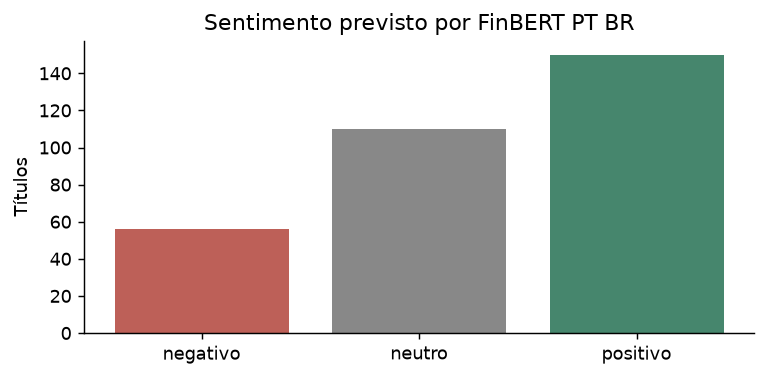

,doc_id,titulo,sentimento_previsto,score_max,p_positivo,p_negativo,p_neutro
0,N001,"IFIX avança 0,43% e alcança 3.956,84 pontos",positivo,0.913057,0.913057,0.042743,0.044200
1,N002,"Dividendos do MCRE11 superam 1,3% em outubro; veja quem recebe",negativo,0.616851,0.271755,0.616851,0.111394
2,N003,"Por dentro do HGLG11: veja os galpões, contratos e dividendos do fundo",neutro,0.811823,0.133293,0.054884,0.811823
3,N004,XPML11 anuncia dividendos para outubro; confira quem terá direito,neutro,0.829078,0.100657,0.070265,0.829078
4,N005,"Semana terá 65 pagamentos de FIIs, com dividend yield de até 1,69%",neutro,0.653900,0.275447,0.070653,0.653900
...,...,...,...,...,...,...,...
311,N312,Vale (VALE3) anuncia lucro 36% maior; confira os resultados do 1T26,positivo,0.916855,0.916855,0.034499,0.048646
312,N313,Petrobras (PETR4) fecha acordo para adquirir parte de campo; veja detalhes,neutro,0.646087,0.299038,0.054875,0.646087
313,N314,"Petrobras, Vale e mais: veja o calendário de resultados do 1T26",neutro,0.792384,0.141744,0.065872,0.792384
314,N315,Banco do Brasil (BBAS3) faz estreia no mercado internacional e capta US$ 500 milhões; entenda,positivo,0.895144,0.895144,0.030085,0.074771


{'realizado': True, 'escopo': 'títulos', 'contagens': {'positivo': 150, 'neutro': 110, 'negativo': 56}}


In [9]:
sentimentos = []
try:
    stok, smodel = carregar("sentimento", AutoModelForSequenceClassification)
    mapa = {0: "positivo", 1: "negativo", 2: "neutro"}
    with torch.inference_mode():
        for i in range(0, len(df), 8):
            lote = df.iloc[i : i + 8]
            entrada = stok(
                lote.titulo.tolist(),
                padding=True,
                truncation=True,
                max_length=256,
                return_tensors="pt",
            )
            probs = smodel(**entrada).logits.softmax(-1).cpu().numpy()
            for (_, r), p in zip(lote.iterrows(), probs):
                sentimentos.append(
                    {
                        "doc_id": r.doc_id,
                        "titulo": r.titulo,
                        "sentimento_previsto": mapa[int(p.argmax())],
                        "score_max": float(p.max()),
                        **{f"p_{mapa[j]}": float(p[j]) for j in range(3)},
                    }
                )
    sentimentos = pd.DataFrame(sentimentos)
    salvar_csv(sentimentos, "sentimentos_titulos.csv")
    status["sentimento"] = {
        "realizado": True,
        "escopo": "títulos",
        "contagens": sentimentos.sentimento_previsto.value_counts().to_dict(),
    }
    cont = sentimentos.sentimento_previsto.value_counts().reindex(
        ["negativo", "neutro", "positivo"], fill_value=0
    )
    plt.figure(figsize=(6, 3))
    plt.bar(cont.index, cont.values, color=["#bd6058", "#888888", "#46866d"])
    plt.ylabel("Títulos")
    plt.title("Sentimento previsto por FinBERT PT BR")
    salvar_fig("03_sentimentos.png")
    display(sentimentos)
except Exception as erro:
    status["sentimento"] = {"realizado": False, "motivo": repr(erro)}
print(status["sentimento"])


## 7. Entidades e relações

Usamos `pt_core_news_sm` nos títulos e corpos, mantendo caixa e pontuação. Salvamos as entidades, os tipos, as posições e o código da notícia.

Para as relações, procuramos uma entidade como sujeito de um verbo e um complemento na mesma frase. Guardamos a frase original e a indicação de negação. São candidatos para revisão: o método não resolve pronomes e pode produzir complementos incompletos ou relações incorretas.


,entidade,tipo,mencoes,documentos
1443,R$,MISC,2076,274
946,Imposto de Renda,MISC,83,80
2056,yield,MISC,98,72
675,FIIs,ORG,149,65
271,Brasil,LOC,88,56
308,CDI,ORG,110,53
650,FII,ORG,73,53
370,CRIs,MISC,106,45
461,Clique,LOC,43,43
157,B3,ORG,76,42


,doc_id,sujeito,verbo,complemento,negacao,evidencia,tipo
0,N001,IFIX,avançar,"0,43%",False,"IFIX avança 0,43% e alcança 3.956,84 pontos.",candidato_sujeito_verbo_complemento
1,N001,IFIX,encerrar,o pregão desta segunda-feira (19),False,"O IFIX encerrou o pregão desta segunda-feira (19) aos 3.956,84 pontos, alta de 0,43%.",candidato_sujeito_verbo_complemento
2,N001,IFIX,encerrar,"aos 3.956,84 pontos, alta de 0,43%",False,"O IFIX encerrou o pregão desta segunda-feira (19) aos 3.956,84 pontos, alta de 0,43%.",candidato_sujeito_verbo_complemento
3,N001,MXRF11,liderar,"Entre os fundos imobiliários mais negociados,",False,"Entre os fundos imobiliários mais negociados, o MXRF11 (Maxi Renda) liderou em volume, com 1,8 milhão de cotas e avanço de 0,43% no dia.",candidato_sujeito_verbo_complemento
4,N001,MXRF11,liderar,em volume,False,"Entre os fundos imobiliários mais negociados, o MXRF11 (Maxi Renda) liderou em volume, com 1,8 milhão de cotas e avanço de 0,43% no dia.",candidato_sujeito_verbo_complemento
5,N001,MXRF11,liderar,", com 1,8 milhão de cotas e avanço de 0,43% no dia",False,"Entre os fundos imobiliários mais negociados, o MXRF11 (Maxi Renda) liderou em volume, com 1,8 milhão de cotas e avanço de 0,43% no dia.",candidato_sujeito_verbo_complemento
6,N001,SNEL11,movimentar,"1,23 milhão de cotas",False,"Na sequência, o GGRC11 (Zagros Renda Imobiliária) somou 1,48 milhão de cotas e valorização de 0,11%, enquanto o SNEL11 (Suno Energias Li...",candidato_sujeito_verbo_complemento
7,N001,SNEL11,movimentar,", com queda de 0,25%",False,"Na sequência, o GGRC11 (Zagros Renda Imobiliária) somou 1,48 milhão de cotas e valorização de 0,11%, enquanto o SNEL11 (Suno Energias Li...",candidato_sujeito_verbo_complemento
8,N001,CLIN11,avançar,"Entre as maiores valorizações do dia,",False,"Entre as maiores valorizações do dia, o CLIN11 (Clave Índices de Preços FII) avançou 2,85% e encerrou cotado a R$ 92,20.",candidato_sujeito_verbo_complemento
9,N001,CLIN11,avançar,"2,85%",False,"Entre as maiores valorizações do dia, o CLIN11 (Clave Índices de Preços FII) avançou 2,85% e encerrou cotado a R$ 92,20.",candidato_sujeito_verbo_complemento


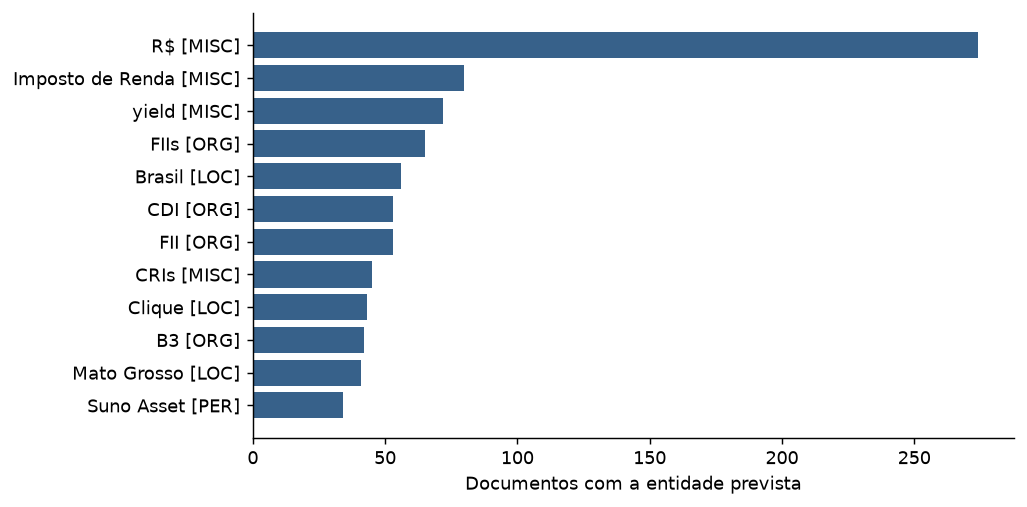

In [10]:
entidades = []
relacoes = []
for r, d in zip(df.itertuples(), docs):
    for e in d.ents:
        entidades.append(
            {
                "doc_id": r.doc_id,
                "entidade": e.text,
                "tipo": e.label_,
                "inicio": e.start_char,
                "fim": e.end_char,
            }
        )
    por_token = {t.i: e for e in d.ents for t in e}
    for v in d:
        if v.pos_ != "VERB":
            continue
        sujeitos = [
            t for t in v.children if t.dep_ in {"nsubj", "csubj"} and t.i in por_token
        ]
        objetos = [t for t in v.children if t.dep_ in {"obj", "iobj", "obl", "attr"}]
        for subj in sujeitos:
            for obj in objetos:
                span = list(obj.subtree)
                if not span:
                    continue
                complemento = d[
                    min(t.i for t in span) : max(t.i for t in span) + 1
                ].text
                if len(complemento) > 200:
                    continue
                relacoes.append(
                    {
                        "doc_id": r.doc_id,
                        "sujeito": por_token[subj.i].text,
                        "verbo": v.lemma_,
                        "complemento": complemento,
                        "negacao": any(
                            t.lower_ in {"não", "nunca", "nem"} for t in v.children
                        ),
                        "evidencia": v.sent.text,
                        "tipo": "candidato_sujeito_verbo_complemento",
                    }
                )
entidades = pd.DataFrame(
    entidades, columns=["doc_id", "entidade", "tipo", "inicio", "fim"]
)
relacoes = pd.DataFrame(
    relacoes,
    columns=[
        "doc_id",
        "sujeito",
        "verbo",
        "complemento",
        "negacao",
        "evidencia",
        "tipo",
    ],
).drop_duplicates()
salvar_csv(entidades, "entidades.csv")
salvar_csv(relacoes, "relacoes_candidatas.csv")
frequencia = (
    entidades.groupby(["entidade", "tipo"])
    .agg(mencoes=("doc_id", "size"), documentos=("doc_id", "nunique"))
    .reset_index()
    .sort_values(["documentos", "mencoes"], ascending=False)
)
salvar_csv(frequencia, "entidades_frequentes.csv")
status["entidades"] = {
    "realizado": True,
    "mencoes": len(entidades),
    "entidades_distintas": len(frequencia),
}
status["relacoes"] = {
    "realizado": True,
    "candidatos": len(relacoes),
    "metodo": "Regra de dependências; candidatos sujeitos a revisão.",
}
display(frequencia.head(25))
display(relacoes.head(30))
top = frequencia.head(12).iloc[::-1]
plt.figure(figsize=(8, 4))
plt.barh(top.entidade + " [" + top.tipo + "]", top.documentos, color="#37618a")
plt.xlabel("Documentos com a entidade prevista")
salvar_fig("04_entidades.png")


## 8. Conferência e arquivos de saída

Salvamos versões, modelos, parâmetros e a identificação da base. As conferências abaixo verificam as buscas, as dimensões dos vetores, as métricas e a separação de treino e teste.

Os CSVs mantêm o código das notícias e as URLs para permitir a consulta às fontes. Os gráficos ficam em `resultados/graficos/`.


In [11]:
pacotes = [
    "pandas",
    "numpy",
    "scipy",
    "scikit-learn",
    "gensim",
    "torch",
    "transformers",
    "spacy",
    "nltk",
    "matplotlib",
    "nbformat",
    "nbclient",
]
versoes = {p: importlib.metadata.version(p) for p in pacotes}
registro = {
    "auditoria": auditoria,
    "status": status,
    "k_candidatos": candidatos,
    "pca": pca_info,
    "python": platform.python_version(),
    "versoes": versoes,
    "modelos": modelos,
    "sha256_base_bruta": hashlib.sha256(
        (BASE / "dados/noticias_financeiras_brutas.csv").read_bytes()
    ).hexdigest(),
    "parametros": {
        "seed": SEED,
        "max_docs": MAX_DOCS,
        "k_testados": list(range(2, min(8, len(df) - 1) + 1)),
        "consultas": CONSULTAS,
    },
}
(RES / "registro_execucao.json").write_text(
    json.dumps(registro, ensure_ascii=False, indent=2)
)
assert len(buscas) == sum(c["consulta_coberta"] for c in cobertura) * 5
assert not buscas.duplicated(["representacao", "consulta", "doc_id"]).any()
assert set(buscas.doc_id).issubset(set(df.doc_id))
assert all(X.shape[0] == len(df) for X in representacoes.values())
assert met.select_dtypes("number").apply(np.isfinite).all().all()
print(
    "Conferências concluídas. Documentos:",
    len(df),
    "| Representações:",
    list(representacoes),
)
print(json.dumps(status, ensure_ascii=False, indent=2))
assert status["classificacao_assunto"]["realizado"]
assert set(particoes[particoes.particao == "treino"].grupo).isdisjoint(
    set(particoes[particoes.particao == "teste"].grupo)
)


Conferências concluídas. Documentos: 316 | Representações: ['BoW', 'TF-IDF', 'Word2Vec', 'BERT']
{
  "lexicais_word2vec": {
    "realizado": true,
    "segundos": 11.576684582978487,
    "vocabulario": 4769,
    "vocabulario_w2v": 5192
  },
  "word2vec_cobertura": 0.9636328476037721,
  "BERT": {
    "realizado": true,
    "dimensoes": 768,
    "segundos": 88.87694345897762
  },
  "classificacao_assunto": {
    "realizado": true,
    "rotulos": "categoria editorial primária do Status Invest",
    "classes": [
      "FIIs",
      "Fiagro",
      "Negócios"
    ],
    "treino": 253,
    "teste": 63,
    "grupos": 310,
    "grupos_compartilhados": 0,
    "validacao": "3 folds agrupados no treino; escolha por F1 macro",
    "modelo_escolhido": "TF-IDF",
    "baseline_acuracia": 0.36507936507936506,
    "baseline_f1_macro": 0.17829457364341084,
    "ajustes": "Regressão Logística, C=1, class_weight=balanced; vocabulário e Word2Vec ajustados apenas no treino",
    "tarefa_binaria": "FIIs vers